In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os
from core.utils import load_predictions, add_confusion_categories


In [52]:
# add_confusion_categories is imported from core.utils (see cell 0)


# **Load data**

In [53]:
SELECTED_VARIABLES = [
    "CBFB-MYH11",
    "IDH2",
    "IDH_mutations",
    "KIT",
    "NPM1",
    "PML-RARA",
    "RTK_RAS_mutations",
    "STAG2",
    "TP53",
    "monosomy5_del_5q",
]

# BONE MARROW:
VAF_DATA_PATH_BM = "data/aml_mut_pred_vaf_values_bm_24-02-2026.xlsx"
SURVIVAL_DATA_PATH_BM = "data/aml_mut_pred_survival_data_bm_24-02-2026.xlsx"
MODEL_PREDICTIONS_PATH_FUSION_BM = "data/scemila_fusion_v15_predictions.csv"

# PERIPHERAL BLOOD:
VAF_DATA_PATH_PB = "data/aml_mut_pred_vaf_values_pb_24-02-2026.xlsx"
SURVIVAL_DATA_PATH_PB = "data/aml_mut_pred_survival_data_pb_24-02-2026.xlsx"
MODEL_PREDICTIONS_PATH_FUSION_PB = "data/<pb_fusion_predictions>.csv"  # TODO: set correct path
USE_DUMMY_DATA = False  # set True to use synthetic data (no real patient files needed)
if USE_DUMMY_DATA:
    VAF_DATA_PATH_BM = "data/dummy/vaf_values_bm.xlsx"
    VAF_DATA_PATH_PB = "data/dummy/vaf_values_pb.xlsx"
    SURVIVAL_DATA_PATH_BM = "data/dummy/survival_data_bm.xlsx"
    SURVIVAL_DATA_PATH_PB = "data/dummy/survival_data_pb.xlsx"
    MODEL_PREDICTIONS_PATH_FUSION_BM = "data/scemila_fusion_v15_predictions.csv"
    MODEL_PREDICTIONS_PATH_FUSION_PB = "data/scemila_fusion_v15_predictions.csv"


### FUSION

### Bone marrow

In [54]:
df_vaf_bm = pd.read_excel(VAF_DATA_PATH_BM)
df_survival_bm = pd.read_excel(SURVIVAL_DATA_PATH_BM)

predicted_labels_bm = load_predictions(MODEL_PREDICTIONS_PATH_FUSION_BM, SELECTED_VARIABLES)
predicted_labels_bm = add_confusion_categories(predicted_labels_bm, SELECTED_VARIABLES, keep_original=True)

### Peripheral blood

In [55]:
df_vaf_pb = pd.read_excel(VAF_DATA_PATH_PB)
df_survival_pb = pd.read_excel(SURVIVAL_DATA_PATH_PB)

#predicted_labels_pb = load_predictions(MODEL_PREDICTIONS_PATH_FUSION_PB, SELECTED_VARIABLES)
#predicted_labels_pb = add_confusion_categories(predicted_labels_pb, SELECTED_VARIABLES, keep_original=True)
#predicted_labels_pb.album_id = predicted_labels_pb.album_id.astype(str)

# **Association of predictions and VAF**

In [88]:
from core.visualization.box_plot import plot_covariate_distributions
from core.visualization.scatter_plot import draw_scatter_plot

def run_all_experiments(df_vaf, predicted_labels, variables_to_plot=None):
    variables = [
        col[: -len("_predicted")]
        for col in predicted_labels.columns
        if col.endswith("_predicted")
    ]

    for variable_name in variables:
        if variables_to_plot is not None and variable_name not in variables_to_plot:
            continue

        if variable_name not in df_vaf.columns:
            print(f"{variable_name} not in VAF table")
            print("-----------------------------------------")
            continue

        # Build per-variable prediction slice
        pred_cols = [
            "album_id", "database_id",
            f"{variable_name}_predicted",
            f"{variable_name}_pred_prob",
        ]
        pred_slice = predicted_labels[[c for c in pred_cols if c in predicted_labels.columns]].copy()
        pred_slice = pred_slice.dropna(subset=f"{variable_name}_predicted")
        pred_slice = pred_slice.rename(columns={
            f"{variable_name}_predicted": "predicted",
            f"{variable_name}_pred_prob": "pred_prob",
        })
        
        df = df_vaf[["henkilotunnus", "album_id", "database_id", variable_name]].merge(
            pred_slice, on=["album_id", "database_id"], how="inner"
        )

        # drop samples with no VAF value
        df = df.dropna(subset=variable_name)

        # drop VAF outliers
        df = df[df[variable_name] <= 100]

        # analyse only truly positive samples (TP + FN)
        df = df[df["predicted"].isin(["TP", "FN"])]
        df["true_positive"] = df["predicted"] == "TP"

        if len(df) > 0:
            print(df["true_positive"].value_counts())

            try:
                print(variable_name)
                plot_covariate_distributions(
                    df,
                    {variable_name: variable_name},
                    "true_positive",
                    fontsize=7,
                    label_mapping={True: "True positive", False: "False negative"},
                    xlabel="",
                    ylabel="VAF (%)",
                    num_columns=1,
                    fig_width=2,
                    fig_height=2,
                )

                draw_scatter_plot(
                    df=df,
                    x_variable="pred_prob",
                    y_variable=variable_name,
                    correlation_method="spearman",
                    show_trendline=False,
                    show_regression=True,
                    show_correlation=True,
                    title=variable_name,
                    x_label="Confidence",
                    y_label="VAF (%)",
                    fontsize=7,
                    show_grid=False,
                    figsize=(2, 2),
                )
            except:
                plt.clf()
        print("-----------------------------------------")

### Bone marrow

CYTOSTASIS PATIENTS
true_positive
True    1
Name: count, dtype: int64
CBFB-MYH11
-----------------------------------------
true_positive
True     11
False     6
Name: count, dtype: int64
IDH2


<Figure size 200x200 with 0 Axes>

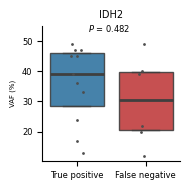

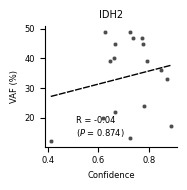

-----------------------------------------
IDH_mutations not in VAF table
-----------------------------------------
true_positive
True     4
False    3
Name: count, dtype: int64
KIT


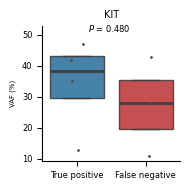

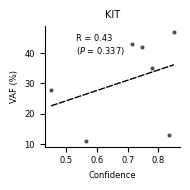

-----------------------------------------
true_positive
True     27
False    10
Name: count, dtype: int64
NPM1


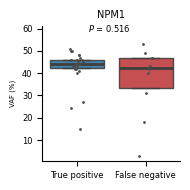

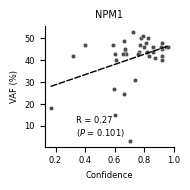

-----------------------------------------
-----------------------------------------
RTK_RAS_mutations not in VAF table
-----------------------------------------
true_positive
True     4
False    2
Name: count, dtype: int64
STAG2


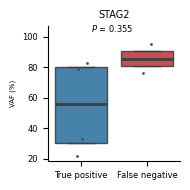

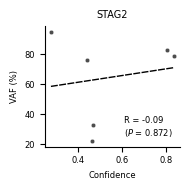

-----------------------------------------
true_positive
False    5
True     1
Name: count, dtype: int64
TP53


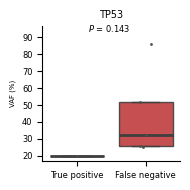

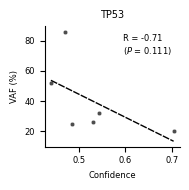

-----------------------------------------
monosomy5_del_5q not in VAF table
-----------------------------------------
ALL PATIENTS
true_positive
True    1
Name: count, dtype: int64
CBFB-MYH11
-----------------------------------------
true_positive
False    22
True     15
Name: count, dtype: int64
IDH2


<Figure size 200x200 with 0 Axes>

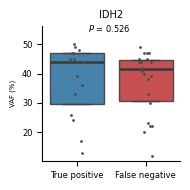

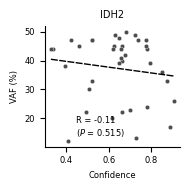

-----------------------------------------
IDH_mutations not in VAF table
-----------------------------------------
true_positive
False    5
True     4
Name: count, dtype: int64
KIT


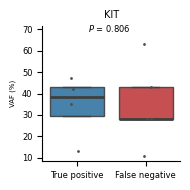

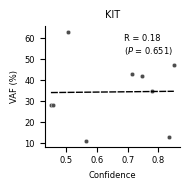

-----------------------------------------
true_positive
True     48
False    20
Name: count, dtype: int64
NPM1


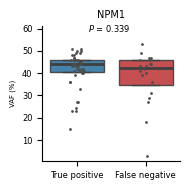

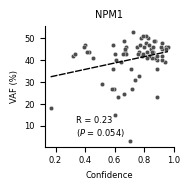

-----------------------------------------
-----------------------------------------
RTK_RAS_mutations not in VAF table
-----------------------------------------
true_positive
True     11
False     4
Name: count, dtype: int64
STAG2


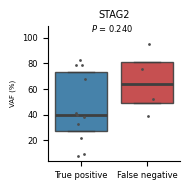

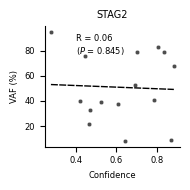

-----------------------------------------
true_positive
False    15
True      8
Name: count, dtype: int64
TP53


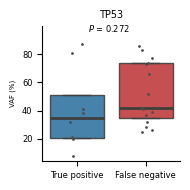

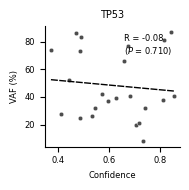

-----------------------------------------
monosomy5_del_5q not in VAF table
-----------------------------------------


In [89]:
df_cyto = df_survival_bm[df_survival_bm.cyto == True]
patients_to_include = df_cyto.henkilotunnus.to_list()
df_vaf_bm_cyto = df_vaf_bm[df_vaf_bm.henkilotunnus.isin(patients_to_include)]

# cytostasis treated patients only
print("CYTOSTASIS PATIENTS")
run_all_experiments(df_vaf_bm_cyto, predicted_labels_bm)

# all available patients
print("ALL PATIENTS")
run_all_experiments(df_vaf_bm, predicted_labels_bm)

### Peripheral blood

In [58]:
run_all_experiments(df_vaf_pb, PREDICTION_RESULTS_DIR_PB)

AttributeError: 'str' object has no attribute 'columns'